# Shortest Path — A* on Road Network
Computes and visualizes the shortest path between two points along segmented roads using A* with Euclidean heuristic.

In [49]:
import heapq
import matplotlib.pyplot as plt
import numpy as np
import cv2

In [50]:
scale = 0.5
start = (100,200)
end = (800,1500)

In [51]:
def resize_grid(grid):
    h, w = grid.shape
    new_size = (int(w*scale), int(h*scale))
    small = cv2.resize(grid, new_size, interpolation=cv2.INTER_NEAREST)
    return small

In [ ]:
mask = cv2.imread("segmented_mask.png", cv2.IMREAD_GRAYSCALE)

if mask is None:
    print("Error: segmented_mask.png not found. Run the segmentation pipeline first.")
    exit()

kernel = np.ones((5,5), np.uint8)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

grid = (mask != 255).astype(np.uint8)  # 0 = road, 1 = obstacle
grid = resize_grid(grid)

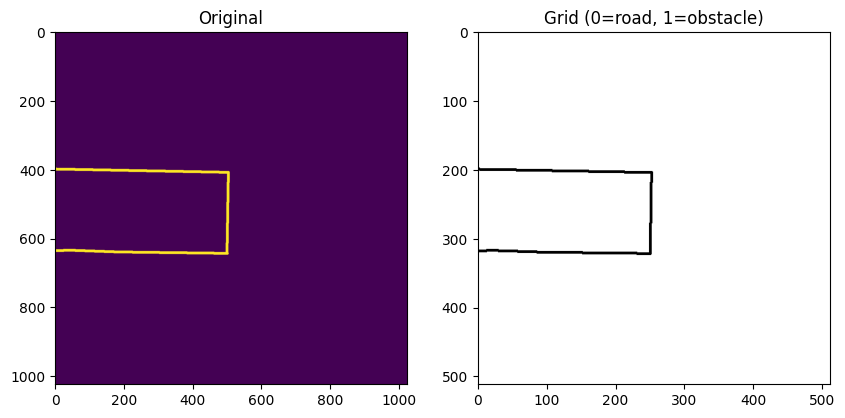

In [53]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(mask)
plt.title("Original")

plt.subplot(1,2,2)
plt.imshow(grid, cmap='gray')
plt.title("Grid (0=road, 1=obstacle)")
plt.show()

In [54]:
class Node:
    def __init__(self, x, y, g=0, h=0, parent=None):
        self.x = x
        self.y = y
        self.g = g
        self.h = h
        self.f = g + h
        self.parent = parent

    def __lt__(self, other):
        return self.f < other.f  # for heapq

In [55]:
def heuristic(x1, y1, x2, y2):
    return ((x1 - x2)**2 + (y1 - y2)**2) ** 0.5  # Euclidean

def is_walkable(x, y):
    return (0 <= x < grid.shape[0] and 
            0 <= y < grid.shape[1] and 
            grid[x][y] == 0)

def reconstruct_path(node):
    path = []
    while node:
        path.append((node.x, node.y))
        node = node.parent
    return path[::-1]

def astar(start, end):
    open_heap = []
    heapq.heappush(open_heap, Node(start[0], start[1]))

    closed_set = set()
    visited = {}  # (x,y) -> g cost

    while open_heap:
        current = heapq.heappop(open_heap)

        if (current.x, current.y) == end:
            return reconstruct_path(current)

        closed_set.add((current.x, current.y))

        directions = [
            (0,1), (1,0), (0,-1), (-1,0),
            (1,1), (1,-1), (-1,1), (-1,-1)
        ]

        for dx, dy in directions:
            nx, ny = current.x + dx, current.y + dy

            if not is_walkable(nx, ny) or (nx, ny) in closed_set:
                continue

            # Prevent diagonal corner cutting
            if dx != 0 and dy != 0:
                if not (is_walkable(current.x + dx, current.y) and 
                        is_walkable(current.x, current.y + dy)):
                    continue

            if dx != 0 and dy != 0:
                new_g = current.g + 1.414  # diagonal
            else:
                new_g = current.g + 1

            if (nx, ny) not in visited or new_g < visited[(nx, ny)]:
                visited[(nx, ny)] = new_g
                h = heuristic(nx, ny, end[0], end[1])
                neighbor = Node(nx, ny, new_g, h, current)
                heapq.heappush(open_heap, neighbor)

    return []  # no path

In [56]:
def snap_to_road(point, grid):
    road_pixels = np.argwhere(grid == 0)  # 0 = road
    if len(road_pixels) == 0:
        return point
    distances = np.linalg.norm(road_pixels - np.array(point), axis=1)
    return tuple(road_pixels[np.argmin(distances)])

Snapped start: (np.int64(200), np.int64(100)), end: (np.int64(323), np.int64(251))
Path found:
[(200, 100), (201, 101), (201, 102), (202, 103), (203, 104), (203, 105), (203, 106), (203, 107), (203, 108), (203, 109), (203, 110), (203, 111), (203, 112), (203, 113), (203, 114), (203, 115), (203, 116), (203, 117), (203, 118), (203, 119), (203, 120), (203, 121), (203, 122), (203, 123), (203, 124), (203, 125), (203, 126), (203, 127), (203, 128), (203, 129), (203, 130), (203, 131), (203, 132), (203, 133), (203, 134), (203, 135), (203, 136), (203, 137), (203, 138), (203, 139), (203, 140), (203, 141), (203, 142), (203, 143), (203, 144), (203, 145), (203, 146), (203, 147), (203, 148), (203, 149), (203, 150), (203, 151), (203, 152), (203, 153), (203, 154), (203, 155), (203, 156), (203, 157), (203, 158), (203, 159), (203, 160), (203, 161), (203, 162), (203, 163), (203, 164), (203, 165), (203, 166), (203, 167), (203, 168), (203, 169), (203, 170), (203, 171), (203, 172), (203, 173), (203, 174), (203

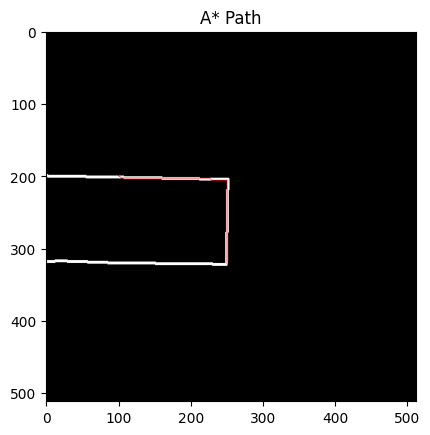

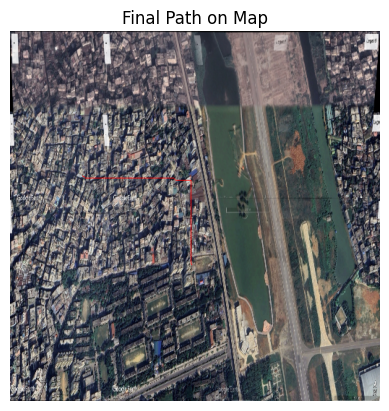

In [59]:
start_scaled = (int(start[0] * scale), int(start[1] * scale))
end_scaled = (int(end[0] * scale), int(end[1] * scale))

START = snap_to_road(start_scaled, grid)
END = snap_to_road(end_scaled, grid)
print(f"Snapped start: {START}, end: {END}")

if not is_walkable(*START):
    print("Start is not on a road")
elif not is_walkable(*END):
    print("End is not on a road")
else: 
    path = astar(START, END)
    path = [(int(x), int(y)) for x, y in path]

    if path:
        print("Path found:")
        print(path)
    else:
        print("No path found")

    vis = cv2.cvtColor((1-grid)*255, cv2.COLOR_GRAY2BGR)

    for x, y in path:
        vis[x, y] = [255, 0, 0]  # red path

    plt.imshow(vis)
    plt.title("A* Path")
    plt.show()

    orig = cv2.imread("topdown_image.png")
    orig = cv2.resize(orig, (grid.shape[1], grid.shape[0]))

    for x, y in path:
        orig[x, y] = [0, 0, 255]

    plt.imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
    plt.title("Final Path on Map")
    plt.axis('off')
    plt.show()